# Week 1 Lesson 4 - Duplicates, Outliers, Missing Data and Checking Data

## Quick question Duplicates

To practise this, let's look at the simple table below, which is a snapshot of exit data collected by volunteers during a recent State Election held in Queensland.



In [19]:
import pandas as pd

data = pd.read_csv('data/week_1_lesson_4_election.csv')

display(data)

,date,age,sex,location,party
0,21 September,29,female,Sandgate,Labor
1,21 September,51,male,Everton Hills,Liberal
2,21 September,51,male,Everton Electorate,Liberal
3,22 September,20,female,Nudgee Electorate,Greens
4,22 September,20,female,Aspley Electorate,Labor
5,22 September,62,female,Nudgee Beach,Labor
6,22 September,25,male,Sandgate Electorate,Greens
7,23 September,27,male,Nudgee Beach,Liberal
8,23 September,59,female,Aspley Heights,Labor
9,23 September,59,female,Aspley Electorate,Labor


In [20]:
# Show all copies of duplicate rows
display(data[data.duplicated(keep=False)])

,date,age,sex,location,party


I will normalise the location column to only keep the first word, so that I can find duplicates by location.

In [21]:
data['location'] = data['location'].str.split().str[0]

display(data)

,date,age,sex,location,party
0,21 September,29,female,Sandgate,Labor
1,21 September,51,male,Everton,Liberal
2,21 September,51,male,Everton,Liberal
3,22 September,20,female,Nudgee,Greens
4,22 September,20,female,Aspley,Labor
5,22 September,62,female,Nudgee,Labor
6,22 September,25,male,Sandgate,Greens
7,23 September,27,male,Nudgee,Liberal
8,23 September,59,female,Aspley,Labor
9,23 September,59,female,Aspley,Labor


In [22]:
display(data[data.duplicated(keep=False)])

,date,age,sex,location,party
1,21 September,51,male,Everton,Liberal
2,21 September,51,male,Everton,Liberal
8,23 September,59,female,Aspley,Labor
9,23 September,59,female,Aspley,Labor


Finding duplicates by also ignoring the date:

In [23]:
display(data[data.duplicated(
    subset=data.columns.drop('date'),
    keep=False
)])

,date,age,sex,location,party
1,21 September,51,male,Everton,Liberal
2,21 September,51,male,Everton,Liberal
8,23 September,59,female,Aspley,Labor
9,23 September,59,female,Aspley,Labor
10,23 September,34,male,Everton,Liberal
11,24 September,34,male,Everton,Liberal


I obtained the 3 pairs discussed in the theory.

## Outliers

In [24]:
import pandas as pd

data = pd.read_csv('data/week_1_lesson_4_payslip.csv')

display(data)

,date,amount
0,10 January,317.59
1,17 January,298.20
2,24 January,269.55
3,31 January,67.80
4,7 February,298.20
5,14 February,305.01
6,21 February,298.20
7,28 February,269.55
8,7 March,317.59
9,21 March,298.20


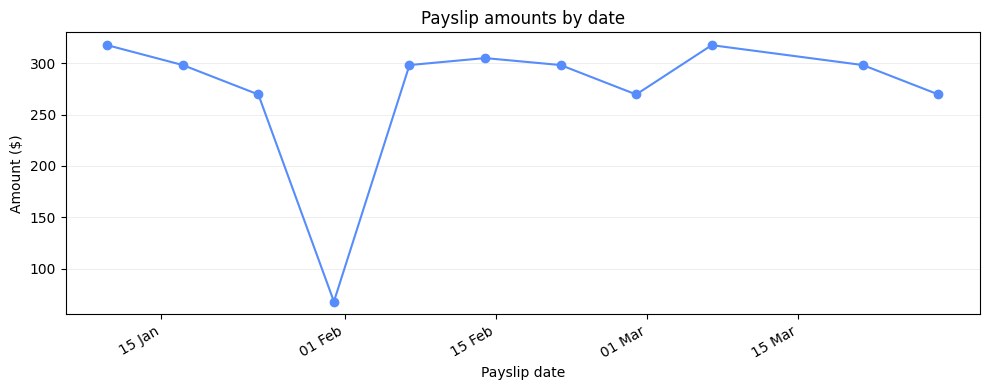

In [25]:
import matplotlib.pyplot as plt

# Convert dates so they are spaced correctly on the chart
data['date'] = pd.to_datetime(data['date'], format='%d %B')

ax = data.plot(
    x='date',
    y='amount',
    marker='o',
    figsize=(10, 4),
    legend=False,
    title='Payslip amounts by date'
)

ax.set_xlabel('Payslip date')
ax.set_ylabel('Amount ($)')
ax.xaxis.set_major_formatter(
    plt.matplotlib.dates.DateFormatter('%d %b')
)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

Finding the outliers using the IQR method. The outliers are the points that are more than 1.5 times the IQR below the first quartile or above the third quartile.

In [26]:
q1 = data['amount'].quantile(0.25)
q3 = data['amount'].quantile(0.75)
iqr = q3 - q1

print(f"Q1: {q1}, Q3: {q3}, IQR: {iqr}")

outliers = data[
    (data['amount'] < q1 - 1.5 * iqr) |
    (data['amount'] > q3 + 1.5 * iqr)
]

display(outliers)

Q1: 269.55, Q3: 301.605, IQR: 32.05500000000001


,date,amount
3,1900-01-31,67.8


### Interquartile Range (IQR)

The **IQR** measures the spread of the middle **50%** of the data.

- **Q1:** The 25th percentile.
- **Q3:** The 75th percentile.
- **IQR = Q3 − Q1**

Potential outliers are values that fall:

- Below **Q1 − 1.5 × IQR**
- Above **Q3 + 1.5 × IQR**

The IQR is useful because it is less affected by extreme values.

## Quick question: Outliers

In [27]:
import pandas as pd

data = pd.read_csv('data/week_1_lesson_4_profit.csv')

display(data)

,month,profit
0,January,35980
1,February,168200
2,March,172439
3,April,162532
4,May,180211
5,June,182955
6,July,174560
7,August,170845
8,September,165230
9,October,177340


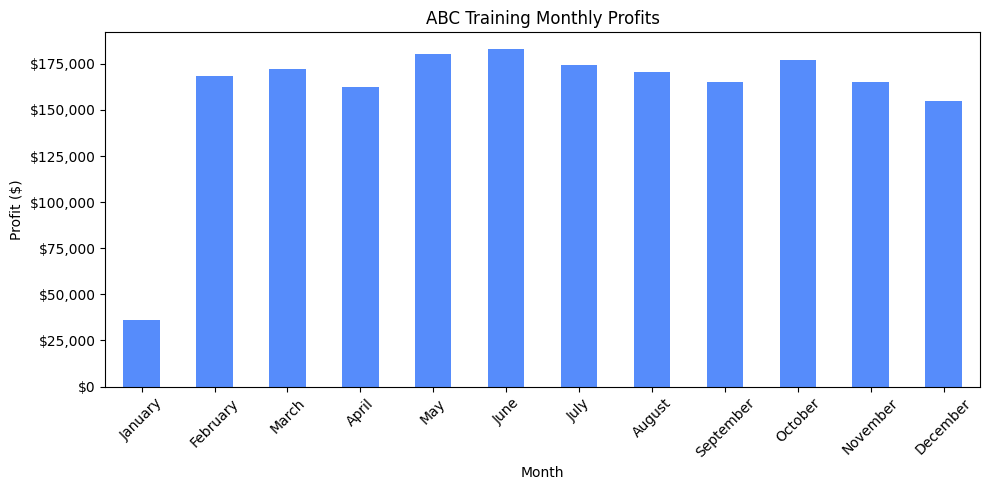

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

data = pd.read_csv('data/week_1_lesson_4_profit.csv')

ax = data.plot.bar(
    x='month',
    y='profit',
    figsize=(10, 5),
    title='ABC Training Monthly Profits',
    legend=False
)

ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))

plt.xlabel('Month')
plt.ylabel('Profit ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
q1 = data['profit'].quantile(0.25)
q3 = data['profit'].quantile(0.75)
iqr = q3 - q1

print(f"Q1: {q1}, Q3: {q3}, IQR: {iqr}")

outliers = data[
    (data['profit'] < q1 - 1.5 * iqr) |
    (data['profit'] > q3 + 1.5 * iqr)
]

display(outliers)

Q1: 164555.5, Q3: 175255.0, IQR: 10699.5


,month,profit
0,January,35980


## Quick question: Missing Data

In [30]:
import pandas as pd

data = pd.read_csv('data/week_1_lesson_4_internet.csv')

display(data)

,company,package,speed_mbps
0,Optus,Standard Plus,47
1,Telstra,Premium,94
2,iiNet,NBN50,51
3,iiNet,#NAME?,91
4,#NAME?,Lite+,50
5,Telstra,Essentials,42
6,Optus,Everyday Plus,#VALUE?
7,#NAME?,Standard +,65
8,iiNET,NBN100,89
9,Telstra,Premium,97


In [31]:
data['speed_mbps'] = pd.to_numeric(data['speed_mbps'], errors='coerce')

speeds = data['speed_mbps']

# Identify the usual range using the IQR
q1 = speeds.quantile(0.25)
q3 = speeds.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Keep speeds within that range
without_outliers = speeds[speeds.between(lower_bound, upper_bound)]

print(f'Average with outliers: {speeds.mean():.2f} Mbps')
print(f'Average without outliers: {without_outliers.mean():.2f} Mbps')
print(f'Median speed: {speeds.median():.2f} Mbps')

Average with outliers: 86.50 Mbps
Average without outliers: 69.56 Mbps
Median speed: 77.00 Mbps


### Why is the median 77 Mbps?

The **median** is the middle value when the data is sorted.

The 10 valid speeds in order are:

42, 47, 50, 51, **65, 89**, 91, 94, 97, 239

Because there is an **even number of values**, the median is the average of the two middle values:

**Median = (65 + 89) / 2 = 77 Mbps**

The median does not have to appear in the original data.

## Quick question: Checking Data

In [32]:
import pandas as pd

data = pd.DataFrame(
    [
        ['China', 'Total', 213954, 243715, 215387, 1433],
        ['China', 'Higher Education', 104269, 125672, 102887, None],
        ['China', 'VET', 94992, 102004, 97419, None],
        ['China', 'ELICOS', 14693, 16039, 15081, None],

        ['India', 'Total', 130745, 142994, 147256, 16511],
        ['India', 'Higher Education', 84467, 92497, 95764, None],
        ['India', 'VET', 45121, 47102, 47911, None],
        ['India', 'ELICOS', 1157, 3395, 3581, None],

        ['Nepal', 'Total', 67542, 69326, 61240, -6302],
        ['Nepal', 'Higher Education', 45366, 46577, 41006, None],
        ['Nepal', 'VET', 21177, 21556, 19654, None],
        ['Nepal', 'ELICOS', 999, 1193, 580, None],

        ['Brazil', 'Total', 40102, 45724, 35670, -4432],
        ['Brazil', 'Higher Education', 29675, 33765, 26874, None],
        ['Brazil', 'VET', 9447, 10673, 8409, None],
        ['Brazil', 'ELICOS', 980, 1286, 387, None],

        ['South Korea', 'Total', 10310, 10935, 8513, -1797],
        ['South Korea', 'Higher Education', 7824, 8002, 6513, None],
        ['South Korea', 'VET', 1973, 2165, 1886, None],
        ['South Korea', 'ELICOS', 513, 768, 114, None],
    ],
    columns=['country', 'education_type', '2018', '2019', '2020', '3_year_change']
)

# Keep change values as integers while allowing missing values
data['3_year_change'] = data['3_year_change'].astype('Int64')

display(data)

,country,education_type,2018,2019,2020,3_year_change
0,China,Total,213954,243715,215387,1433
1,China,Higher Education,104269,125672,102887,<NA>
2,China,VET,94992,102004,97419,<NA>
3,China,ELICOS,14693,16039,15081,<NA>
4,India,Total,130745,142994,147256,16511
5,India,Higher Education,84467,92497,95764,<NA>
6,India,VET,45121,47102,47911,<NA>
7,India,ELICOS,1157,3395,3581,<NA>
8,Nepal,Total,67542,69326,61240,-6302
9,Nepal,Higher Education,45366,46577,41006,<NA>


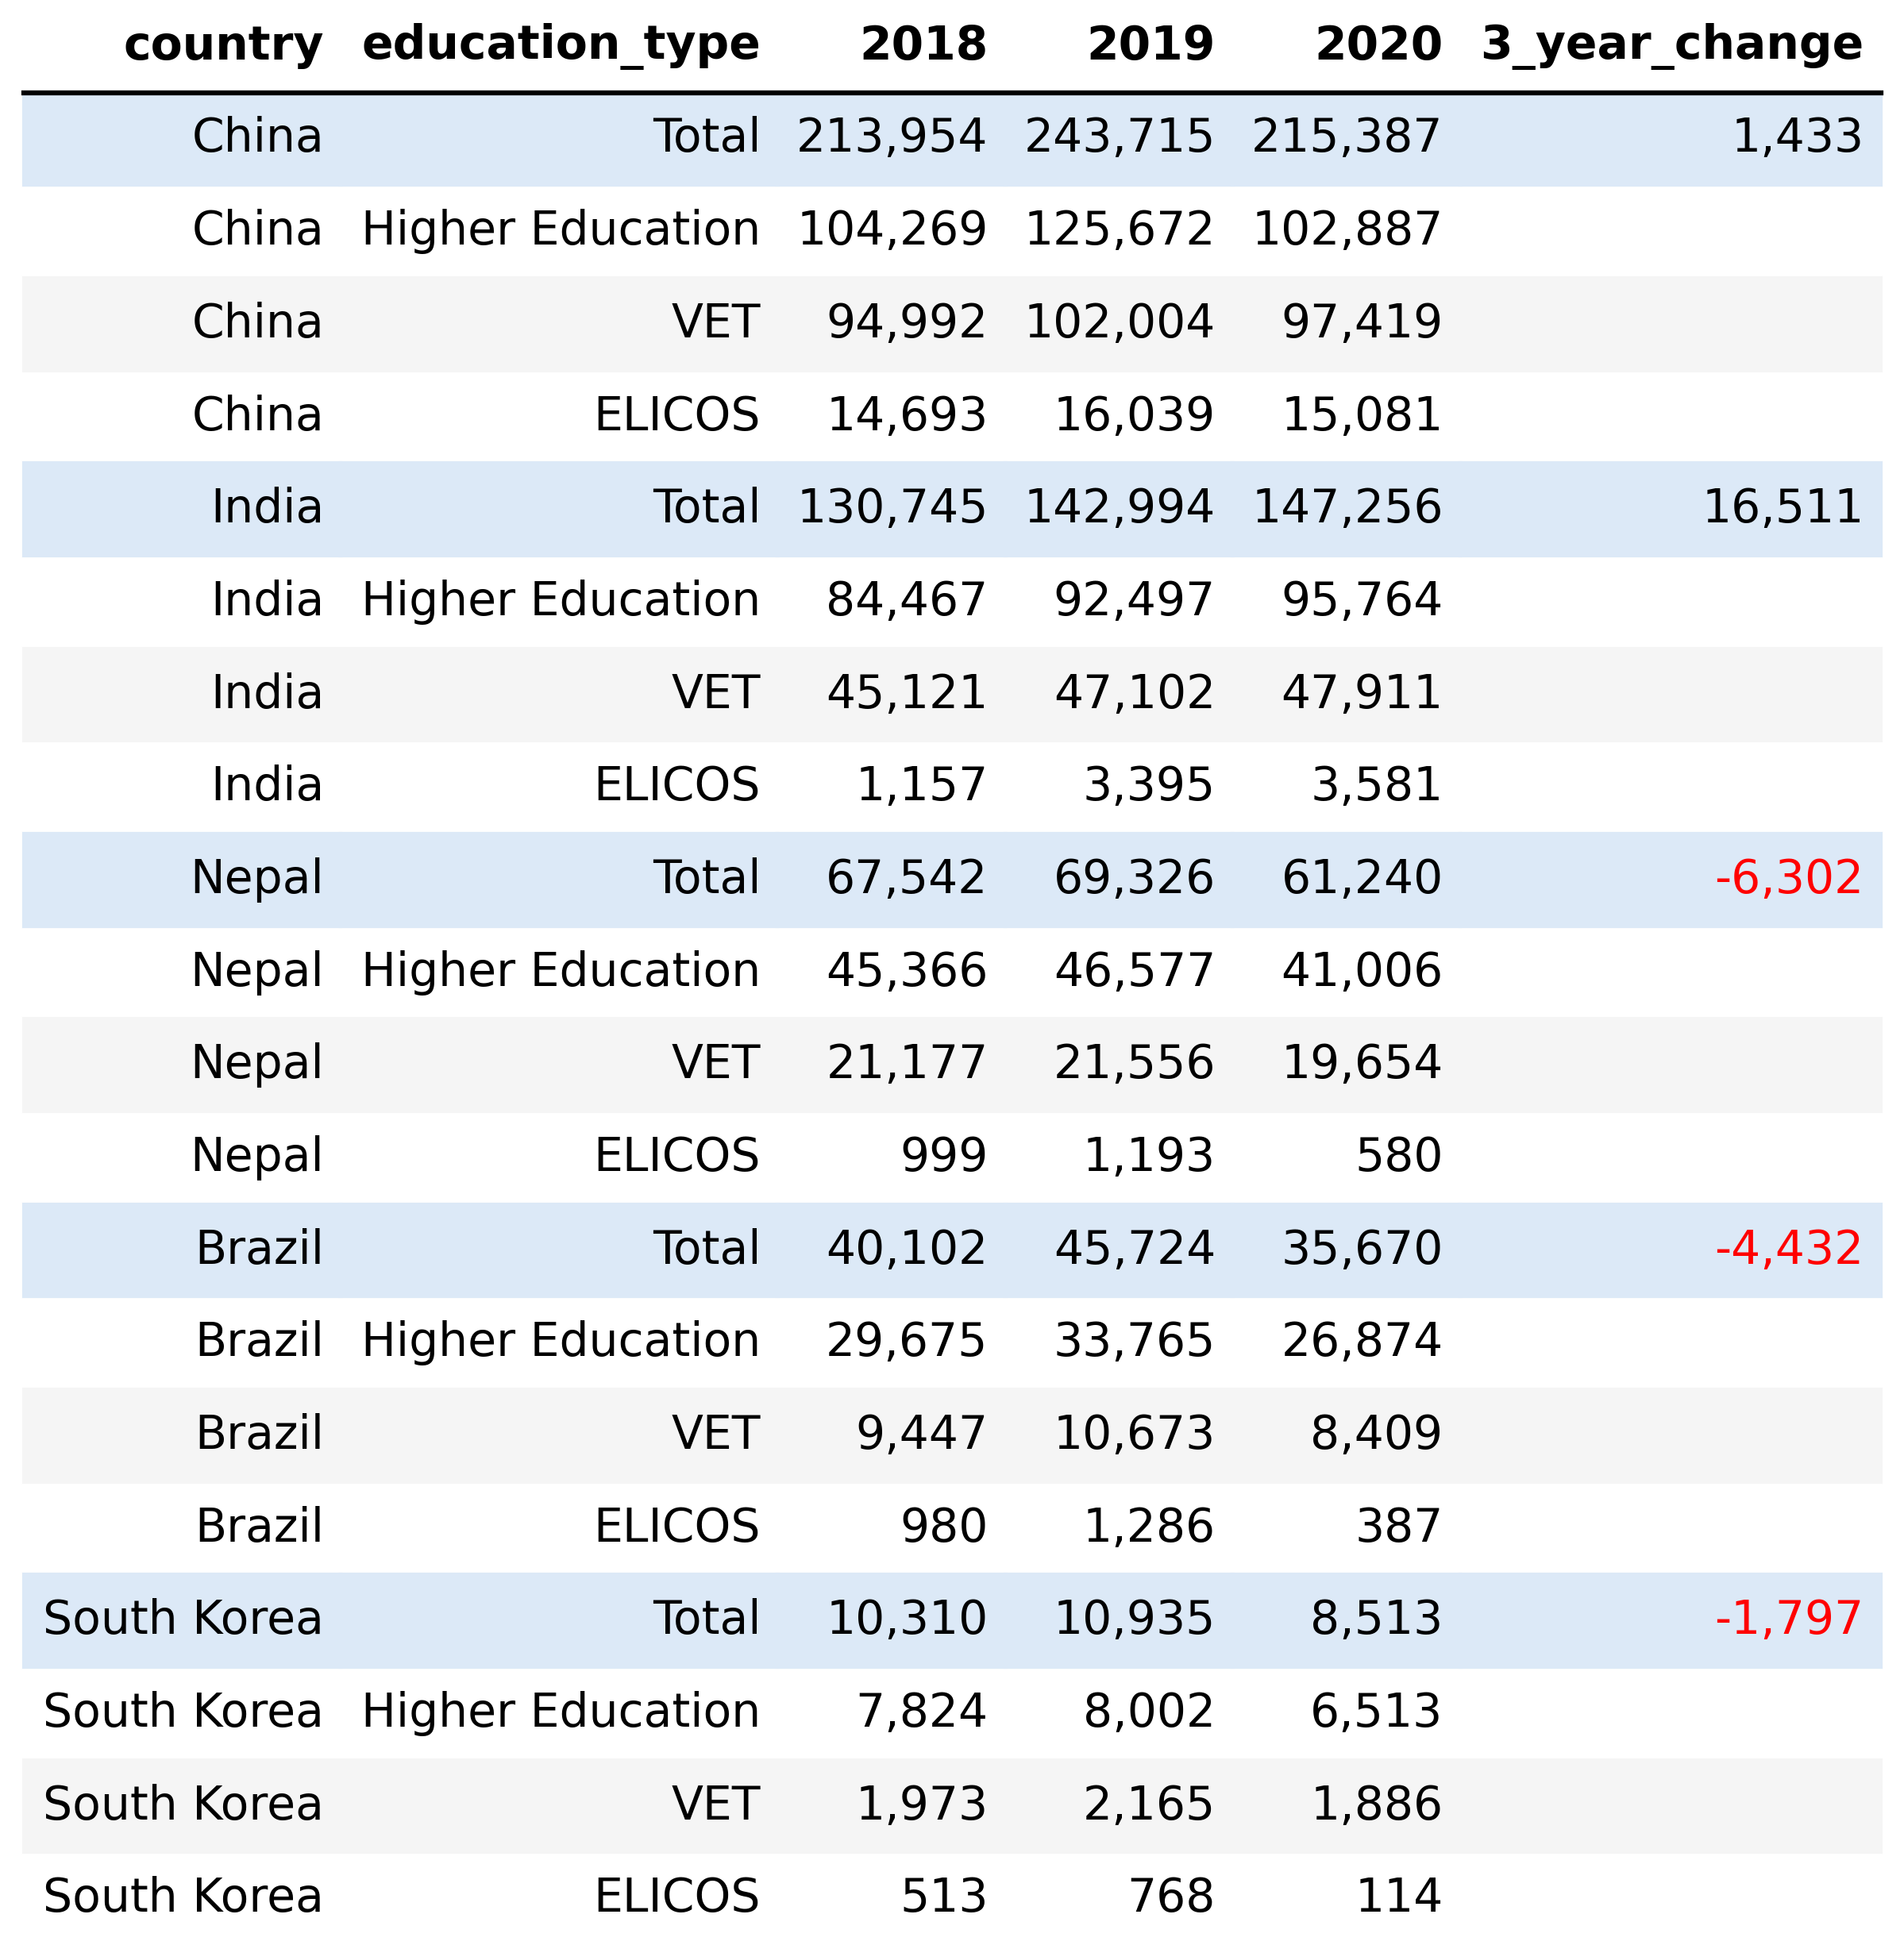

In [33]:
def highlight_totals(row):
    color = 'background-color: #dce9f7' if row['education_type'] == 'Total' else ''
    return [color] * len(row)

def highlight_negative(value):
    return 'color: red' if pd.notna(value) and value < 0 else ''

styled_data = (
    data.style
    .format({
        '2018': '{:,.0f}',
        '2019': '{:,.0f}',
        '2020': '{:,.0f}',
        '3_year_change': '{:,.0f}'
    }, na_rep='')
    .apply(highlight_totals, axis=1)
    .map(highlight_negative, subset=['3_year_change'])
    .hide(axis='index')
)

#display(styled_data) # Does not work when exporting to PDF with nbconvert
# To be able to export it with nbconvert
from pathlib import Path
from IPython.display import Image, display
import dataframe_image as dfi

image_path = Path("images/week_1/education_table.png")
image_path.parent.mkdir(parents=True, exist_ok=True)

dfi.export(
    styled_data,
    str(image_path),
    table_conversion="matplotlib",
    dpi=300
)

display(Image(filename=str(image_path)))

Creating the dataset that can be used for ML:

In [34]:
enrolments = (
    data.loc[data['education_type'] != 'Total']
    .melt(
        id_vars=['country', 'education_type'],
        value_vars=['2018', '2019', '2020'],
        var_name='Year',
        value_name='Enrolments'
    )
    .rename(columns={
        'country': 'Country',
        'education_type': 'Sector'
    })
)

enrolments['Year'] = enrolments['Year'].astype(int)

enrolments = enrolments.sort_values(
    ['Country', 'Sector', 'Year']
).reset_index(drop=True)

display(enrolments)

,Country,Sector,Year,Enrolments
0,Brazil,ELICOS,2018,980
1,Brazil,ELICOS,2019,1286
2,Brazil,ELICOS,2020,387
3,Brazil,Higher Education,2018,29675
4,Brazil,Higher Education,2019,33765
5,Brazil,Higher Education,2020,26874
6,Brazil,VET,2018,9447
7,Brazil,VET,2019,10673
8,Brazil,VET,2020,8409
9,China,ELICOS,2018,14693


Calculating countries totals:

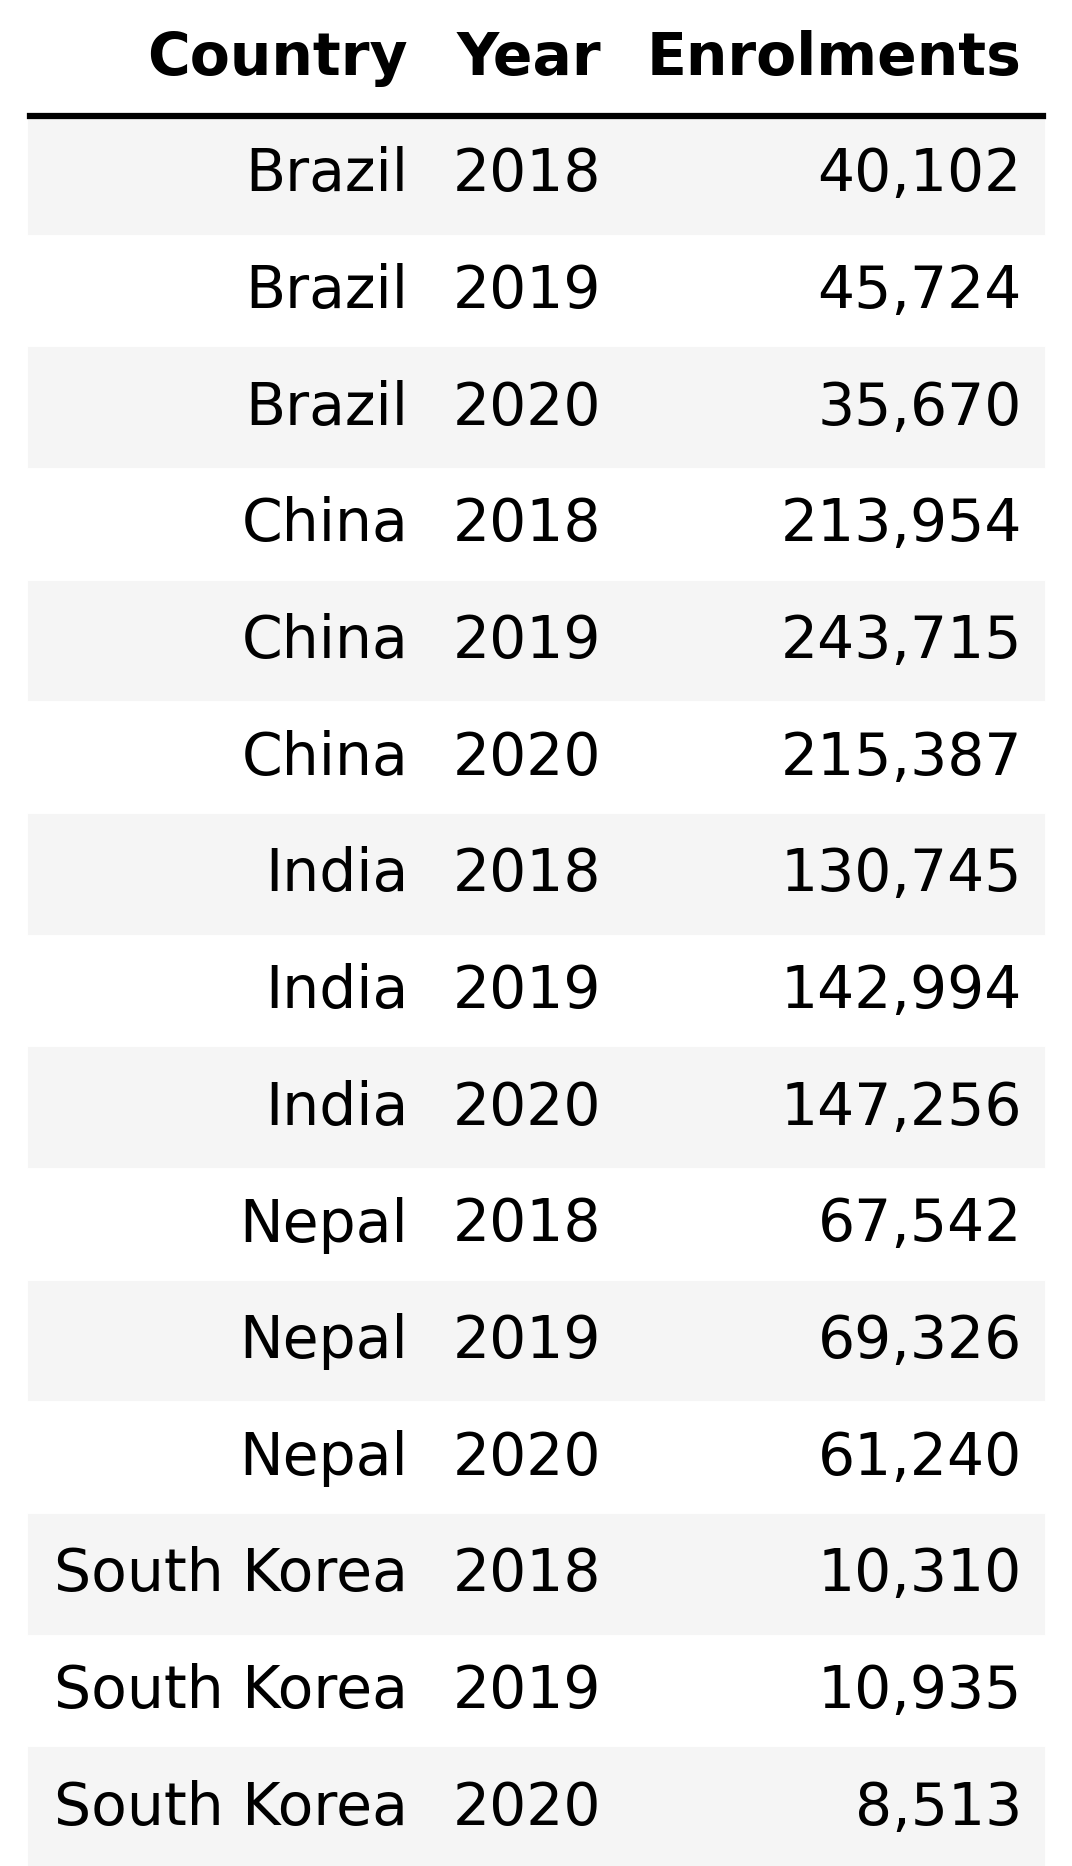

In [35]:
country_totals = (
    enrolments.groupby(['Country', 'Year'], as_index=False)['Enrolments']
    .sum()
)

#display(country_totals.style.format({'Enrolments': '{:,.0f}'}).hide(axis='index'))
# nbconvert does not support the above style, so we will export it as an image to be able to include it in the PDF
styled_country_totals = (
    country_totals.style
    .format({'Enrolments': '{:,.0f}'})
    .hide(axis='index')
)

image_path = Path("images/week_1/country_totals.png")
image_path.parent.mkdir(parents=True, exist_ok=True)

dfi.export(
    styled_country_totals,
    str(image_path),
    table_conversion="matplotlib",
    dpi=300
)

display(Image(filename=str(image_path)))

Country summary table with 3-year change:

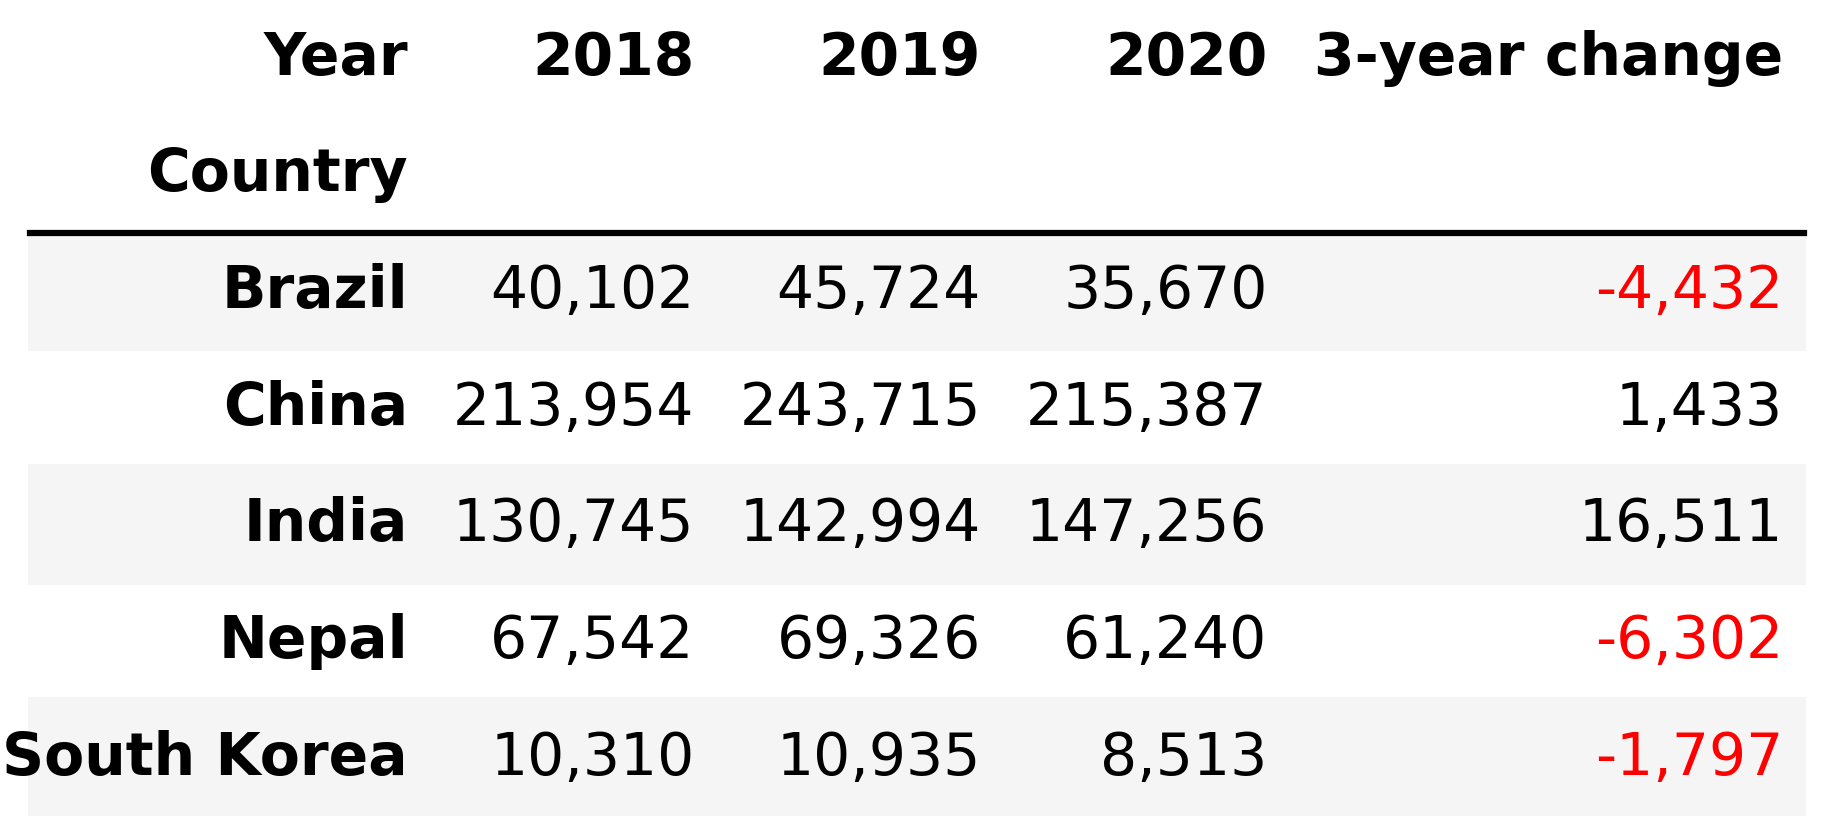

In [36]:
country_summary = country_totals.pivot(
    index='Country',
    columns='Year',
    values='Enrolments'
)

country_summary['3-year change'] = (
    country_summary[2020] - country_summary[2018]
)

'''
display(
    country_summary.style
    .format('{:,.0f}')
    .map(
        lambda value: 'color: red' if value < 0 else '',
        subset=['3-year change']
    )
)
'''

styled_country_summary = (
    country_summary.style
    .format('{:,.0f}', na_rep='')
    .map(
        lambda value: 'color: red'
        if pd.notna(value) and value < 0 else '',
        subset=['3-year change']
    )
)

image_path = Path("images/week_1/country_summary.png")
image_path.parent.mkdir(parents=True, exist_ok=True)

dfi.export(
    styled_country_summary,
    str(image_path),
    table_conversion="matplotlib",
    dpi=300
)

display(Image(filename=str(image_path)))

All the values match!